In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path

# Locate project directory
current_path = Path.cwd()

if current_path.name == "notebooks":
    project_path = current_path.parent
else:
    project_path = current_path

# Load retail dataset
retail_path = project_path / "data" / "raw" / "retail_all_cities.csv"

retail_df = pd.read_csv(retail_path)

print("Retail dataset loaded successfully!")

Retail dataset loaded successfully!


In [3]:
print(retail_df.head(5))

      retail_id       city      state     store_name           category  \
0  RET_HYD_0001  Hyderabad  Telangana   Fresh Mart 1        Supermarket   
1  RET_HYD_0002  Hyderabad  Telangana  City Market 2        Supermarket   
2  RET_HYD_0003  Hyderabad  Telangana  Daily Needs 3  Convenience Store   
3  RET_HYD_0004  Hyderabad  Telangana  Daily Needs 4     Clothing Store   
4  RET_HYD_0005  Hyderabad  Telangana   Urban Shop 5  Convenience Store   

    latitude  longitude  simulated_daily_visitors data_source  is_synthetic  
0  17.459543  78.347957                       305   Synthetic          True  
1  17.406672  78.262713                       211   Synthetic          True  
2  17.376874  78.260614                       427   Synthetic          True  
3  17.357223  78.361276                        33   Synthetic          True  
4  17.319088  78.312192                       709   Synthetic          True  


In [5]:
retail_df.tail()

,retail_id,city,state,store_name,category,latitude,longitude,simulated_daily_visitors,data_source,is_synthetic
3495,RET_LUC_0346,Lucknow,Uttar Pradesh,Urban Shop 346,Supermarket,26.782714,81.064259,776,Synthetic,True
3496,RET_LUC_0347,Lucknow,Uttar Pradesh,Urban Shop 347,Grocery Store,26.968971,81.045820,1317,Synthetic,True
3497,RET_LUC_0348,Lucknow,Uttar Pradesh,Urban Shop 348,Convenience Store,26.834127,80.922298,242,Synthetic,True
3498,RET_LUC_0349,Lucknow,Uttar Pradesh,Mega Mart 349,Clothing Store,26.900913,80.936756,129,Synthetic,True
3499,RET_LUC_0350,Lucknow,Uttar Pradesh,Urban Shop 350,Supermarket,26.790066,80.896685,378,Synthetic,True


In [6]:
print("Number of rows:", retail_df.shape[0])
print("Number of columns:", retail_df.shape[1])

Number of rows: 3500
Number of columns: 10


In [4]:
retail_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   retail_id                 3500 non-null   object 
 1   city                      3500 non-null   object 
 2   state                     3500 non-null   object 
 3   store_name                3500 non-null   object 
 4   category                  3500 non-null   object 
 5   latitude                  3500 non-null   float64
 6   longitude                 3500 non-null   float64
 7   simulated_daily_visitors  3500 non-null   int64  
 8   data_source               3500 non-null   object 
 9   is_synthetic              3500 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(6)
memory usage: 249.6+ KB


In [5]:
retail_df.describe()

,latitude,longitude,simulated_daily_visitors
count,3500.000000,3500.000000,3500.000000
mean,20.902945,77.789730,767.610857
std,5.332867,4.457645,429.774345
min,12.801335,72.452607,20.000000
25%,17.375400,73.874830,385.000000
50%,20.846366,77.374719,772.000000
75%,26.842017,80.224515,1146.000000
max,28.749778,88.448748,1499.000000


In [6]:
print(retail_df.columns.tolist())

['retail_id', 'city', 'state', 'store_name', 'category', 'latitude', 'longitude', 'simulated_daily_visitors', 'data_source', 'is_synthetic']


In [7]:
# Check missing values in each column
missing_values = retail_df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
retail_id                   0
city                        0
state                       0
store_name                  0
category                    0
latitude                    0
longitude                   0
simulated_daily_visitors    0
data_source                 0
is_synthetic                0
dtype: int64

Total Missing Values: 0


In [8]:
# Check complete duplicate rows
print("Duplicate rows:", retail_df.duplicated().sum())

# Check duplicate retail IDs
print("Duplicate Retail IDs:", retail_df["retail_id"].duplicated().sum())

Duplicate rows: 0
Duplicate Retail IDs: 0


In [9]:
category_counts = retail_df["category"].value_counts()

print(category_counts)

category
Clothing Store       885
Supermarket          878
Grocery Store        874
Convenience Store    863
Name: count, dtype: int64


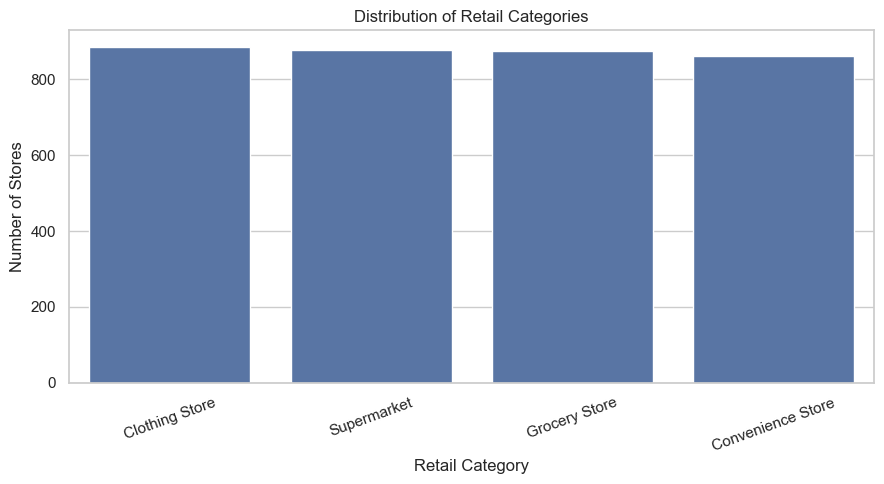

In [10]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=retail_df,
    x="category",
    order=retail_df["category"].value_counts().index
)

plt.title("Distribution of Retail Categories")
plt.xlabel("Retail Category")
plt.ylabel("Number of Stores")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:
city_counts = retail_df["city"].value_counts()

print(city_counts)

city
Hyderabad    350
Bengaluru    350
Chennai      350
Mumbai       350
Delhi        350
Kolkata      350
Pune         350
Ahmedabad    350
Jaipur       350
Lucknow      350
Name: count, dtype: int64


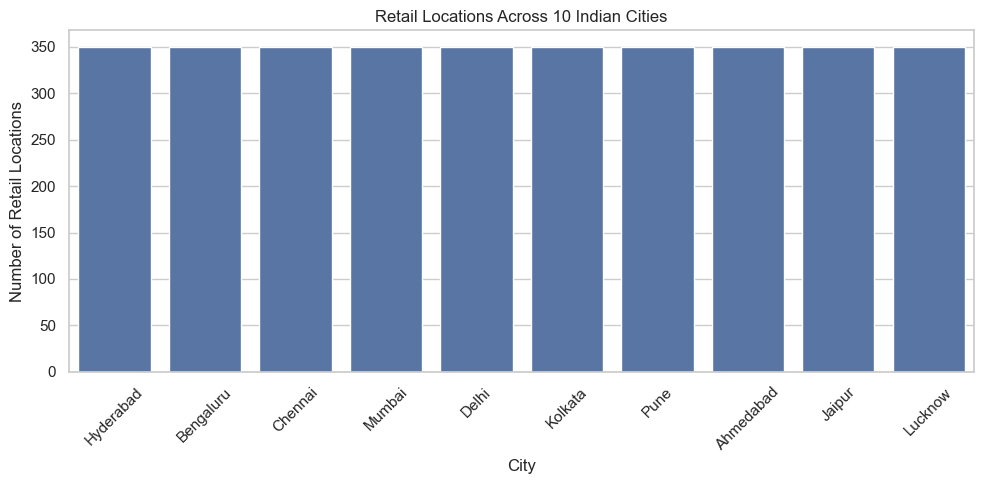

In [12]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=retail_df,
    x="city",
    order=retail_df["city"].value_counts().index
)

plt.title("Retail Locations Across 10 Indian Cities")
plt.xlabel("City")
plt.ylabel("Number of Retail Locations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
print("Latitude Range:")
print("Minimum:", retail_df["latitude"].min())
print("Maximum:", retail_df["latitude"].max())

print("\nLongitude Range:")
print("Minimum:", retail_df["longitude"].min())
print("Maximum:", retail_df["longitude"].max())

Latitude Range:
Minimum: 12.801335
Maximum: 28.749778

Longitude Range:
Minimum: 72.452607
Maximum: 88.448748


In [14]:
retail_df["simulated_daily_visitors"].describe()

count    3500.000000
mean      767.610857
std       429.774345
min        20.000000
25%       385.000000
50%       772.000000
75%      1146.000000
max      1499.000000
Name: simulated_daily_visitors, dtype: float64

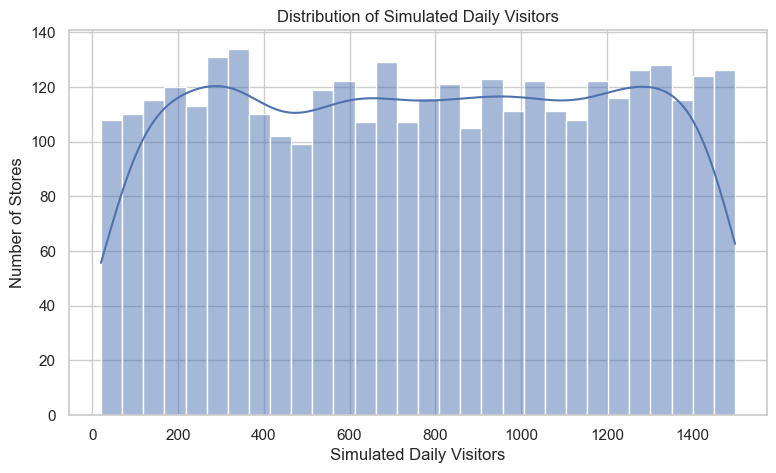

In [15]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=retail_df,
    x="simulated_daily_visitors",
    bins=30,
    kde=True
)

plt.title("Distribution of Simulated Daily Visitors")
plt.xlabel("Simulated Daily Visitors")
plt.ylabel("Number of Stores")
plt.show()

In [16]:
category_visitors = retail_df.groupby("category")[
    "simulated_daily_visitors"
].agg(["count", "mean", "median", "sum"])

category_visitors = category_visitors.sort_values(
    by="mean", ascending=False
)

category_visitors

,count,mean,median,sum
category,,,,
Clothing Store,885,781.510734,788.0,691637
Grocery Store,874,766.248284,765.0,669701
Supermarket,878,764.953303,789.0,671629
Convenience Store,863,757.440324,731.0,653671


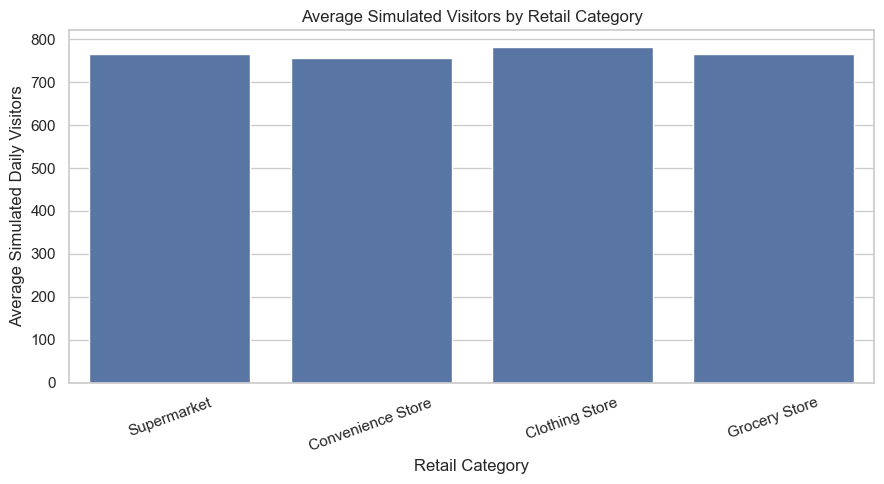

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=retail_df,
    x="category",
    y="simulated_daily_visitors",
    estimator="mean",
    errorbar=None
)

plt.title("Average Simulated Visitors by Retail Category")
plt.xlabel("Retail Category")
plt.ylabel("Average Simulated Daily Visitors")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [18]:
city_visitors = retail_df.groupby("city")[
    "simulated_daily_visitors"
].agg(["count", "mean", "median", "sum"])

city_visitors = city_visitors.sort_values(
    by="mean", ascending=False
)

city_visitors

,count,mean,median,sum
city,,,,
Mumbai,350,797.691429,865.5,279192
Delhi,350,782.965714,795.0,274038
Chennai,350,780.482857,768.0,273169
Bengaluru,350,777.894286,770.5,272263
Hyderabad,350,767.917143,798.0,268771
Kolkata,350,761.874286,770.5,266656
Jaipur,350,753.477143,743.0,263717
Lucknow,350,753.157143,772.0,263605
Pune,350,752.254286,751.0,263289


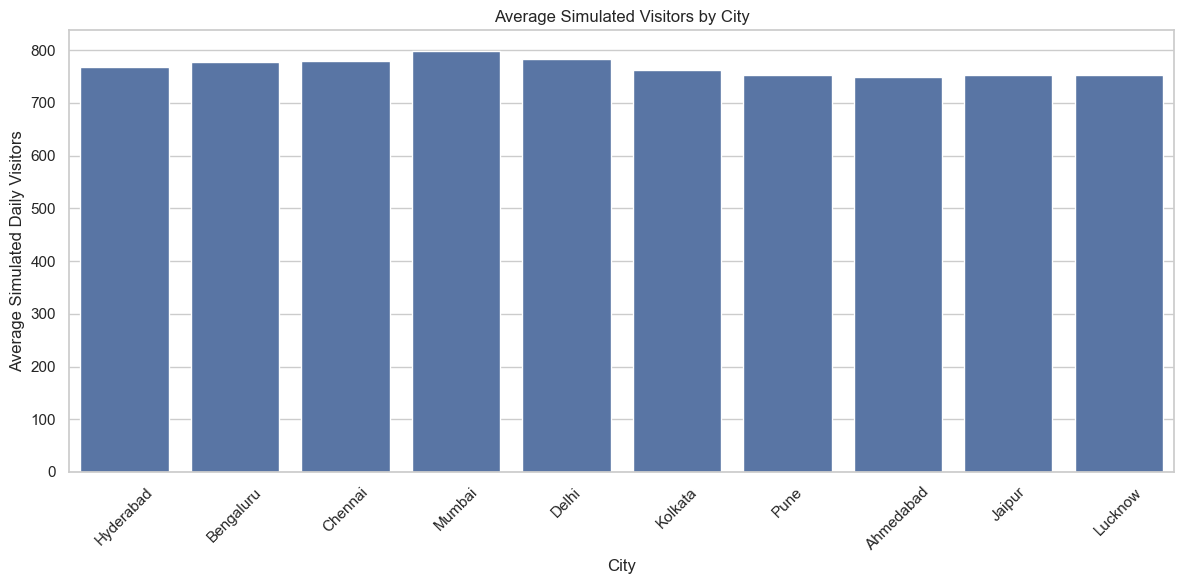

In [19]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=retail_df,
    x="city",
    y="simulated_daily_visitors",
    estimator="mean",
    errorbar=None
)

plt.title("Average Simulated Visitors by City")
plt.xlabel("City")
plt.ylabel("Average Simulated Daily Visitors")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [4]:
# Check latitude and longitude ranges

print("Latitude range:")
print("Minimum:", retail_df["latitude"].min())
print("Maximum:", retail_df["latitude"].max())

print("\nLongitude range:")
print("Minimum:", retail_df["longitude"].min())
print("Maximum:", retail_df["longitude"].max())

Latitude range:
Minimum: 12.801335
Maximum: 28.749778

Longitude range:
Minimum: 72.452607
Maximum: 88.448748


In [5]:
invalid_coordinates = retail_df[
    (~retail_df["latitude"].between(-90, 90)) |
    (~retail_df["longitude"].between(-180, 180))
]

print("Invalid coordinate records:", len(invalid_coordinates))

Invalid coordinate records: 0


In [6]:
print("Visitors less than or equal to zero:",
      (retail_df["simulated_daily_visitors"] <= 0).sum())

Visitors less than or equal to zero: 0


In [7]:
mobility_path = project_path / "data" / "raw" / "mobility_all_cities.csv"

mobility_df = pd.read_csv(mobility_path)

print("Dataset Shape:", mobility_df.shape)

mobility_df.head()

Dataset Shape: (1500, 10)


,mobility_id,city,state,location_name,mobility_type,latitude,longitude,simulated_daily_passengers,data_source,is_synthetic
0,MOB_HYD_0001,Hyderabad,Telangana,Junction Metro Station 1,Metro Station,17.263365,78.554815,3752,Synthetic,True
1,MOB_HYD_0002,Hyderabad,Telangana,East Public Transport Platform 2,Public Transport Platform,17.442882,78.439579,3336,Synthetic,True
2,MOB_HYD_0003,Hyderabad,Telangana,North Metro Station 3,Metro Station,17.414646,78.406057,899,Synthetic,True
3,MOB_HYD_0004,Hyderabad,Telangana,Main Road Bus Stop 4,Bus Stop,17.298326,78.643398,806,Synthetic,True
4,MOB_HYD_0005,Hyderabad,Telangana,Junction Railway Station 5,Railway Station,17.386693,78.456828,3230,Synthetic,True


In [8]:
mobility_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   mobility_id                 1500 non-null   object 
 1   city                        1500 non-null   object 
 2   state                       1500 non-null   object 
 3   location_name               1500 non-null   object 
 4   mobility_type               1500 non-null   object 
 5   latitude                    1500 non-null   float64
 6   longitude                   1500 non-null   float64
 7   simulated_daily_passengers  1500 non-null   int64  
 8   data_source                 1500 non-null   object 
 9   is_synthetic                1500 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(6)
memory usage: 107.1+ KB


In [9]:
mobility_df.describe()

,latitude,longitude,simulated_daily_passengers
count,1500.000000,1500.000000,1500.000000
mean,20.900273,77.790238,2540.094667
std,5.336282,4.461381,1458.675656
min,12.801010,72.450945,50.000000
25%,17.375317,73.874975,1271.000000
50%,20.849466,77.374576,2530.000000
75%,26.823411,80.212258,3845.750000
max,28.749992,88.448980,5000.000000


In [10]:
mobility_df.isnull().sum()

mobility_id                   0
city                          0
state                         0
location_name                 0
mobility_type                 0
latitude                      0
longitude                     0
simulated_daily_passengers    0
data_source                   0
is_synthetic                  0
dtype: int64

In [11]:
print("Total missing values:", mobility_df.isnull().sum().sum())

Total missing values: 0


In [12]:
print("Duplicate rows:", mobility_df.duplicated().sum())

print(
    "Duplicate Mobility IDs:",
    mobility_df["mobility_id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Mobility IDs: 0


In [13]:
mobility_type_counts = mobility_df["mobility_type"].value_counts()

print(mobility_type_counts)

mobility_type
Bus Stop                     409
Metro Station                372
Public Transport Platform    366
Railway Station              353
Name: count, dtype: int64


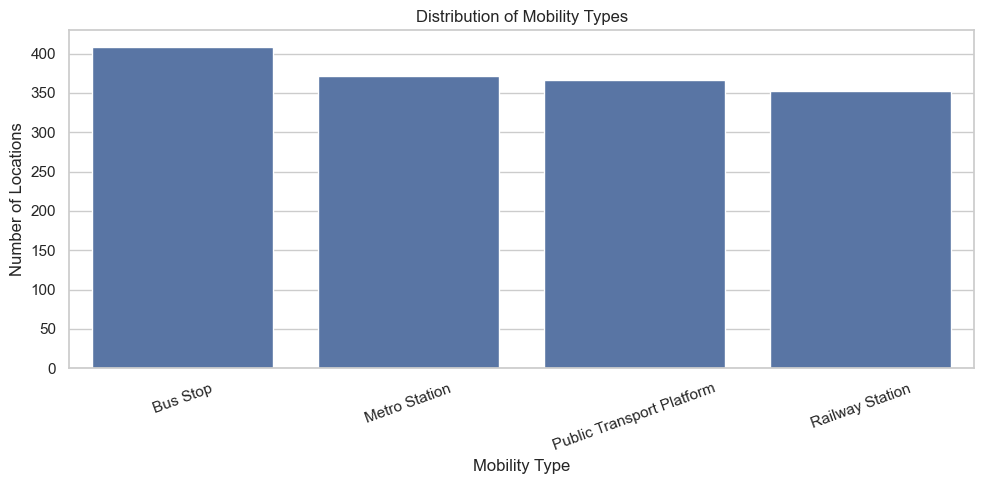

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=mobility_df,
    x="mobility_type",
    order=mobility_type_counts.index
)

plt.title("Distribution of Mobility Types")
plt.xlabel("Mobility Type")
plt.ylabel("Number of Locations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()